# Rock–Paper–Scissors: Pretrained CNN Implementation

**Experiments:** MobileNetV2, ResNet50, EfficientNetB0  
**Modes per architecture:** Frozen feature extractor and fine-tuned feature extractor  
**Total experiments:** 6

For every experiment this notebook generates:
- Training vs validation accuracy curve
- Training vs validation loss curve
- Test-set classification report (precision, recall, F1-score, support)
- Test-set confusion matrix
- Training history and evaluation metrics saved to disk

It also checks training/validation curves for possible overfitting or underfitting and uses augmentation, dropout, weight decay, early stopping, and learning-rate reduction to help control them.

**Important:** Run all cells in Google Colab with a GPU if available. The notebook does not invent results; all metrics are produced by actual model training.

## 1. Install and import libraries

In [1]:
!pip -q install tensorflow scikit-learn pandas matplotlib seaborn pillow

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os, random, zipfile, json, time, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from tensorflow.keras import layers, regularizers, Model
from tensorflow.keras.applications import MobileNetV2, ResNet50, EfficientNetB0
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: []


## 2. Locate and extract the dataset

In [5]:
from google.colab import files

uploaded = files.upload()

Saving dataset.zip to dataset.zip


In [6]:
import zipfile
import os

zip_path = "/content/dataset.zip"
extract_path = "/content/rps_data"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [7]:
import os

for root, dirs, files in os.walk("/content/rps_data"):
    if set(["rock", "paper", "scissors"]).issubset(set(dirs)):
        DATASET_DIR = root
        break

print("Dataset location:", DATASET_DIR)

for cls in ["rock", "paper", "scissors"]:
    folder = os.path.join(DATASET_DIR, cls)
    print(cls, ":", len(os.listdir(folder)), "images")

Dataset location: /content/rps_data/dataset
rock : 200 images
paper : 200 images
scissors : 200 images


In [8]:
from pathlib import Path

DATASET_DIR = Path(DATASET_DIR)

CLASS_NAMES = ["rock", "paper", "scissors"]
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
MAX_EPOCHS = 40

## 3. Build a reproducible stratified 70/15/15 split

In [9]:
CLASS_NAMES = ["rock", "paper", "scissors"]
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
MAX_EPOCHS = 40  # Required range: 30–50. You can change this to 30 or 50.

image_paths, labels = [], []
valid_ext = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for label, class_name in enumerate(CLASS_NAMES):
    class_dir = DATASET_DIR / class_name
    files = sorted([p for p in class_dir.iterdir() if p.is_file() and p.suffix.lower() in valid_ext])
    for p in files:
        image_paths.append(str(p))
        labels.append(label)

image_paths = np.array(image_paths)
labels = np.array(labels)

if len(image_paths) == 0:
    raise ValueError("No images found. Check DATASET_DIR and class folder names.")

train_paths, temp_paths, y_train, y_temp = train_test_split(
    image_paths, labels, test_size=0.30, random_state=SEED, stratify=labels
)
val_paths, test_paths, y_val, y_test = train_test_split(
    temp_paths, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print(f"Train: {len(train_paths)} ({len(train_paths)/len(image_paths):.0%})")
print(f"Validation: {len(val_paths)} ({len(val_paths)/len(image_paths):.0%})")
print(f"Test: {len(test_paths)} ({len(test_paths)/len(image_paths):.0%})")
print("Class order:", CLASS_NAMES)

Train: 420 (70%)
Validation: 90 (15%)
Test: 90 (15%)
Class order: ['rock', 'paper', 'scissors']


## 4. Input pipeline and augmentation

In [10]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, tf.one_hot(label, depth=3)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
], name="data_augmentation")

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_paths, y_train, training=True)
val_ds = make_dataset(val_paths, y_val, training=False)
test_ds = make_dataset(test_paths, y_test, training=False)

## 5. Model builder

Each architecture uses ImageNet pretrained weights and a new three-class classification head. The frozen mode trains only the new head. The fine-tuned mode first trains the head, then unfreezes the top portion of the backbone at a lower learning rate. Batch Normalization layers remain frozen for more stable fine-tuning on a small dataset.

In [11]:
BACKBONES = {
    "MobileNetV2": (MobileNetV2, mobilenet_preprocess),
    "ResNet50": (ResNet50, resnet_preprocess),
    "EfficientNetB0": (EfficientNetB0, efficientnet_preprocess),
}

def build_model(architecture, fine_tune=False):
    backbone_class, preprocess_fn = BACKBONES[architecture]
    base = backbone_class(
        include_top=False, weights="imagenet",
        input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
    )
    base.trainable = False

    inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
    x = layers.Lambda(preprocess_fn, name="preprocess")(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.40)(x)
    x = layers.Dense(128, activation="relu",
                     kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.30)(x)
    outputs = layers.Dense(3, activation="softmax")(x)

    model = Model(inputs, outputs, name=f"{architecture}_RPS")
    return model, base

def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

## 6. Callbacks to reduce overfitting

In [12]:
def get_callbacks(run_dir):
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=7, restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.3, patience=3,
            min_lr=1e-7, verbose=1
        ),
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(run_dir / "best_model.keras"),
            monitor="val_loss", save_best_only=True, verbose=1
        )
    ]

## 7. Training and evaluation function

Each mode is trained for up to `MAX_EPOCHS` (40 by default). Fine-tuning divides the epoch budget into head training and fine-tuning, while keeping the total maximum at 40 epochs. Early stopping may stop earlier if validation loss stops improving.

In [13]:
OUTPUT_DIR = Path("/content/rps_pretrained_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

all_summary_rows = []

def plot_history(history, architecture, mode, run_dir):
    hist = history.history
    epochs = range(1, len(hist["accuracy"]) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, hist["accuracy"], label="Train Accuracy")
    plt.plot(epochs, hist["val_accuracy"], label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{architecture} - {mode}: Accuracy")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(run_dir / "accuracy_curve.png", dpi=150)
    plt.show()
    plt.close()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, hist["loss"], label="Train Loss")
    plt.plot(epochs, hist["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{architecture} - {mode}: Loss")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(run_dir / "loss_curve.png", dpi=150)
    plt.show()
    plt.close()

def assess_fit(history):
    tr_acc = history.history["accuracy"][-1]
    va_acc = history.history["val_accuracy"][-1]
    tr_loss = history.history["loss"][-1]
    va_loss = history.history["val_loss"][-1]
    gap = tr_acc - va_acc

    if tr_acc > 0.90 and gap > 0.10:
        diagnosis = "Possible overfitting: training accuracy is much higher than validation accuracy."
        action = "Use stronger augmentation/dropout, weight decay, fewer trainable layers, or more real images."
    elif tr_acc < 0.65 and va_acc < 0.65:
        diagnosis = "Possible underfitting: both training and validation accuracy are low."
        action = "Train longer, slightly increase model capacity, or carefully unfreeze more backbone layers."
    else:
        diagnosis = "No strong overfitting/underfitting signal from the final accuracy values."
        action = "Review curves and test metrics; keep regularization and early stopping."
    return diagnosis, action, gap, tr_loss, va_loss

def run_experiment(architecture, mode):
    run_name = f"{architecture}_{mode}"
    run_dir = OUTPUT_DIR / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    model, base = build_model(architecture)
    fine_tune = (mode == "Fine-tuned")

    if not fine_tune:
        compile_model(model, 1e-3)
        history = model.fit(
            train_ds, validation_data=val_ds, epochs=MAX_EPOCHS,
            callbacks=get_callbacks(run_dir), verbose=1
        )
    else:
        # Reserve about 20% of total epochs for training the new classification head.
        head_epochs = max(5, int(MAX_EPOCHS * 0.20))
        fine_epochs = max(1, MAX_EPOCHS - head_epochs)

        compile_model(model, 1e-3)
        hist_head = model.fit(
            train_ds, validation_data=val_ds, epochs=head_epochs,
            callbacks=get_callbacks(run_dir), verbose=1
        )

        # Unfreeze top 30% of backbone layers; keep BatchNorm frozen.
        base.trainable = True
        fine_tune_at = int(len(base.layers) * 0.70)
        for layer in base.layers[:fine_tune_at]:
            layer.trainable = False
        for layer in base.layers[fine_tune_at:]:
            if isinstance(layer, layers.BatchNormalization):
                layer.trainable = False

        compile_model(model, 1e-5)
        hist_ft = model.fit(
            train_ds, validation_data=val_ds, epochs=fine_epochs,
            callbacks=get_callbacks(run_dir), verbose=1
        )

        # Combine histories so the curves show all training phases.
        combined = {}
        for key in hist_head.history:
            combined[key] = hist_head.history[key] + hist_ft.history[key]
        history = type("CombinedHistory", (), {"history": combined})()

    plot_history(history, architecture, mode, run_dir)

    # Predict on the untouched test set.
    y_prob = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    report_dict = classification_report(
        y_test, y_pred, labels=[0,1,2], target_names=CLASS_NAMES,
        output_dict=True, zero_division=0
    )
    report_text = classification_report(
        y_test, y_pred, labels=[0,1,2], target_names=CLASS_NAMES,
        zero_division=0
    )
    print(f"\n===== {run_name}: TEST CLASSIFICATION REPORT =====")
    print(report_text)

    with open(run_dir / "classification_report.txt", "w") as f:
        f.write(report_text)
    pd.DataFrame(report_dict).transpose().to_csv(run_dir / "classification_report.csv")

    cm = confusion_matrix(y_test, y_pred, labels=[0,1,2])
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"{architecture} - {mode}: Test Confusion Matrix")
    plt.tight_layout()
    plt.savefig(run_dir / "confusion_matrix.png", dpi=150)
    plt.show()
    plt.close()

    diagnosis, action, gap, tr_loss, va_loss = assess_fit(history)
    print("Fit diagnosis:", diagnosis)
    print("Suggested action:", action)

    accuracy = accuracy_score(y_test, y_pred)
    row = {
        "Architecture": architecture,
        "Mode": mode,
        "Test Accuracy": accuracy,
        "Macro Precision": report_dict["macro avg"]["precision"],
        "Macro Recall": report_dict["macro avg"]["recall"],
        "Macro F1": report_dict["macro avg"]["f1-score"],
        "Epochs Completed": len(history.history["accuracy"]),
        "Train-Val Accuracy Gap": gap,
        "Fit Diagnosis": diagnosis,
        "Suggested Action": action
    }
    with open(run_dir / "fit_diagnosis.json", "w") as f:
        json.dump({"diagnosis": diagnosis, "suggested_action": action,
                   "accuracy_gap": gap, "final_train_loss": tr_loss,
                   "final_val_loss": va_loss}, f, indent=2)

    model.save(run_dir / "final_model.keras")
    pd.DataFrame(history.history).to_csv(run_dir / "training_history.csv", index=False)
    all_summary_rows.append(row)
    return row

## 8. Run all six experiments


Starting: MobileNetV2 Frozen
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5720 - loss: 1.1626
Epoch 1: val_loss improved from None to 0.12464, saving model to /content/rps_pretrained_results/MobileNetV2_Frozen/best_model.keras

Epoch 1: finished saving model to /content/rps_pretrained_results/MobileNetV2_Frozen/best_model.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.7190 - loss: 0.7575 - val_accuracy: 0.9556 - val_loss: 0.1246 - learning_rate: 0.0010
Epoch 2/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9164 - loss: 0.2412
Epoch 2: val_loss improved from 0.12464 to 0.04611, saving model to /content/rps_pretrained_results/MobileNetV2_Frozen/best_model.keras

Epoch 2: finished saving model to /content/rps_pretrained_results/MobileNetV2_Frozen/best_model.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 30s 2s/step - accuracy: 0.9286 - loss: 0.2096 - val_accuracy: 0.9889 - val_loss: 0.0461 - learning_rate: 0.0010
Ep

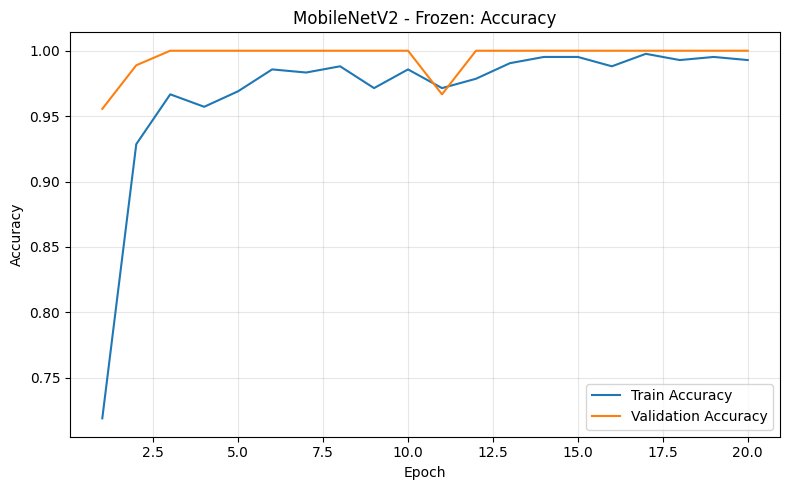

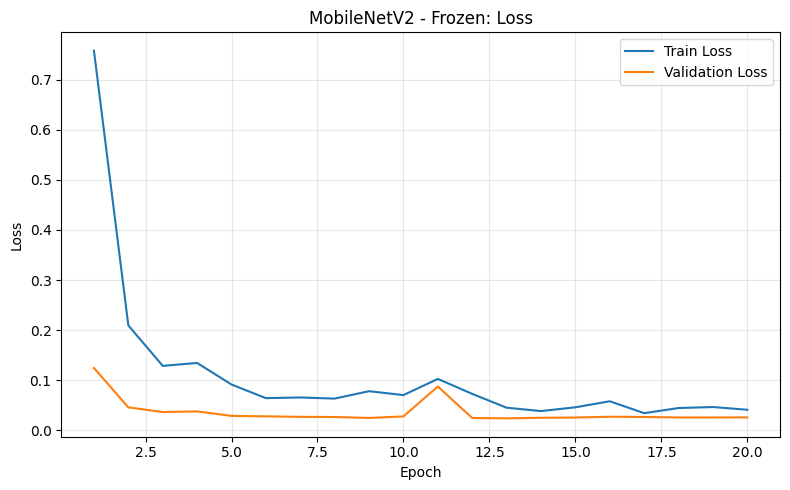


===== MobileNetV2_Frozen: TEST CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        rock       1.00      1.00      1.00        30
       paper       1.00      1.00      1.00        30
    scissors       1.00      1.00      1.00        30

    accuracy                           1.00        90
   macro avg       1.00      1.00      1.00        90
weighted avg       1.00      1.00      1.00        90



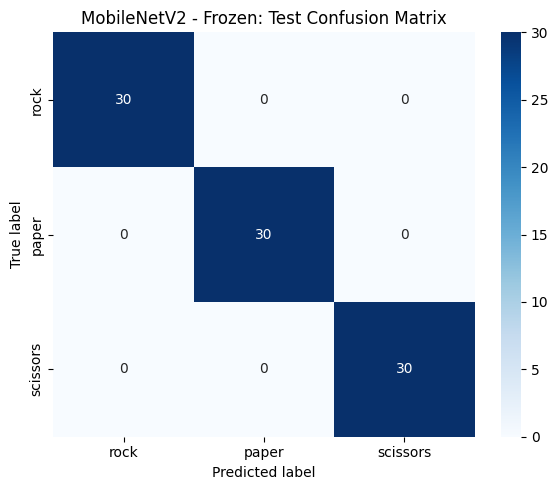

Fit diagnosis: No strong overfitting/underfitting signal from the final accuracy values.
Suggested action: Review curves and test metrics; keep regularization and early stopping.

Starting: MobileNetV2 Fine-tuned
Epoch 1/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6616 - loss: 0.7844
Epoch 1: val_loss improved from None to 0.06887, saving model to /content/rps_pretrained_results/MobileNetV2_Fine-tuned/best_model.keras

Epoch 1: finished saving model to /content/rps_pretrained_results/MobileNetV2_Fine-tuned/best_model.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.8048 - loss: 0.4815 - val_accuracy: 0.9889 - val_loss: 0.0689 - learning_rate: 0.0010
Epoch 2/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9641 - loss: 0.1605
Epoch 2: val_loss improved from 0.06887 to 0.05034, saving model to /content/rps_pretrained_results/MobileNetV2_Fine-tuned/best_model.keras

Epoch 2: finished saving model to /content/rps_pretrained_results/MobileNetV2_Fine-tuned/best_model

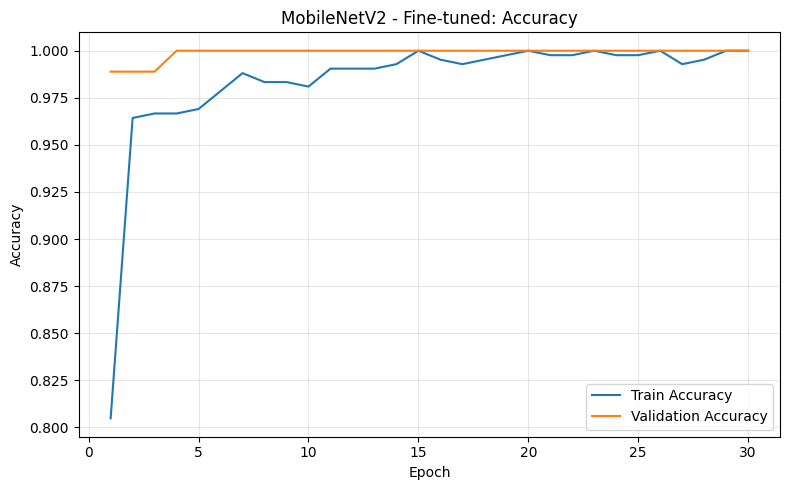

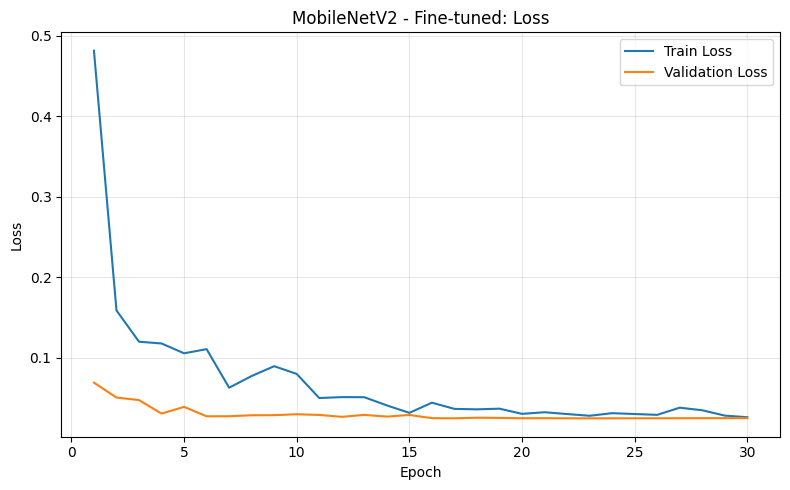


===== MobileNetV2_Fine-tuned: TEST CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        rock       1.00      1.00      1.00        30
       paper       0.97      1.00      0.98        30
    scissors       1.00      0.97      0.98        30

    accuracy                           0.99        90
   macro avg       0.99      0.99      0.99        90
weighted avg       0.99      0.99      0.99        90



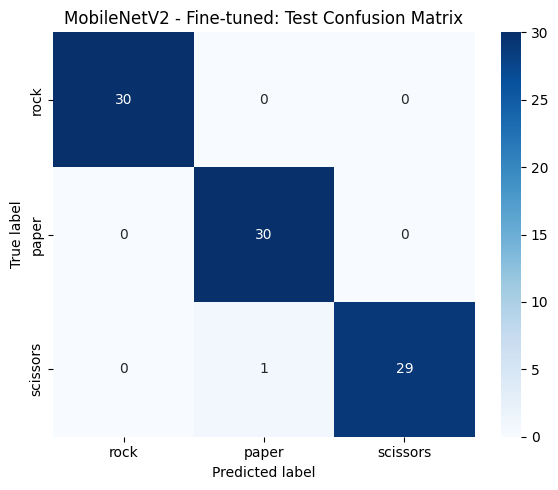

Fit diagnosis: No strong overfitting/underfitting signal from the final accuracy values.
Suggested action: Review curves and test metrics; keep regularization and early stopping.

Starting: ResNet50 Frozen
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.6602 - loss: 0.9037
Epoch 1: val_loss improved from None to 0.18540, saving model to /content/rps_pretrained_results/ResNet50_Frozen/best_model.keras

Epoch 1: finished saving model to /content/rps_pretrained_results/ResNet50_Frozen/best_model.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 125s 8s/step - accuracy: 0.7643 - loss: 0.6525 - val_accuracy: 0.9333 - val_loss: 0.1854 - learning_rate: 0.0010
Epoch 2/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.9428 - loss: 0.2151
Epoch 2: val_loss improved from 0.18540 to 0.07371, saving model to /content/rps_pretrained_results/ResNet50_Frozen/best_model.keras

Epoch 2: finished saving model to /content/rps_pretrained_results/ResNet5

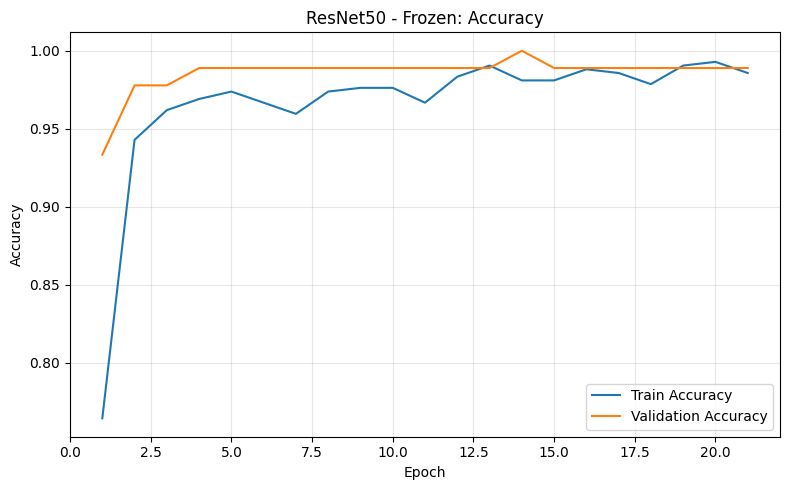

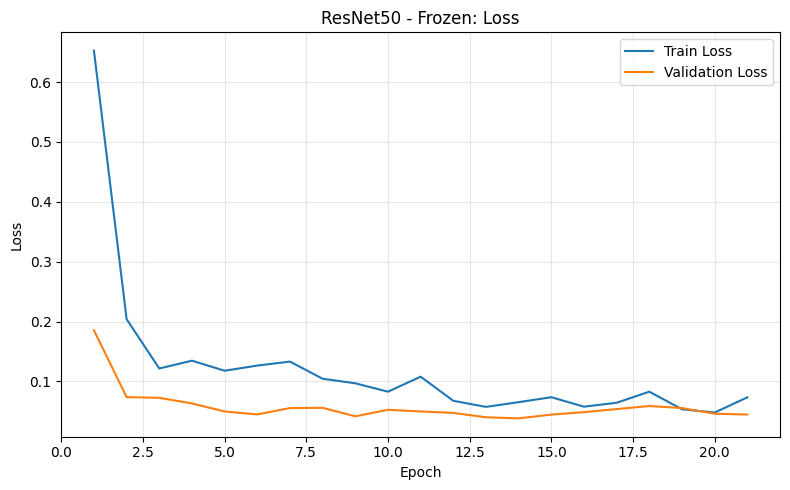


===== ResNet50_Frozen: TEST CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        rock       1.00      1.00      1.00        30
       paper       1.00      1.00      1.00        30
    scissors       1.00      1.00      1.00        30

    accuracy                           1.00        90
   macro avg       1.00      1.00      1.00        90
weighted avg       1.00      1.00      1.00        90



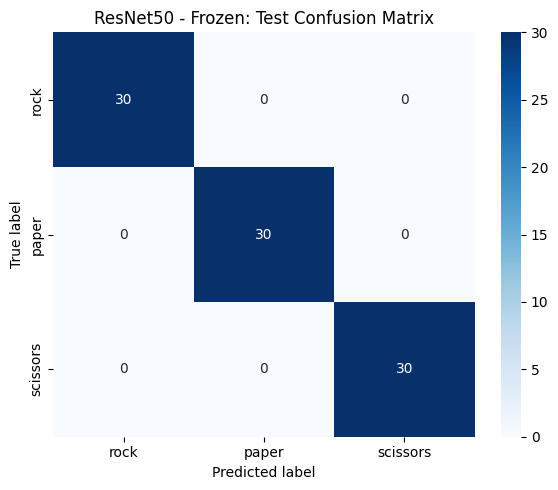

Fit diagnosis: No strong overfitting/underfitting signal from the final accuracy values.
Suggested action: Review curves and test metrics; keep regularization and early stopping.

Starting: ResNet50 Fine-tuned
Epoch 1/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.4765 - loss: 1.8199
Epoch 1: val_loss improved from None to 0.48617, saving model to /content/rps_pretrained_results/ResNet50_Fine-tuned/best_model.keras

Epoch 1: finished saving model to /content/rps_pretrained_results/ResNet50_Fine-tuned/best_model.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 121s 8s/step - accuracy: 0.5857 - loss: 1.3892 - val_accuracy: 0.7889 - val_loss: 0.4862 - learning_rate: 0.0010
Epoch 2/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8367 - loss: 0.3955
Epoch 2: val_loss improved from 0.48617 to 0.10927, saving model to /content/rps_pretrained_results/ResNet50_Fine-tuned/best_model.keras

Epoch 2: finished saving model to /content/rps_pretrained_results/ResNet50_Fine-tuned/best_model.keras
14/14 ━

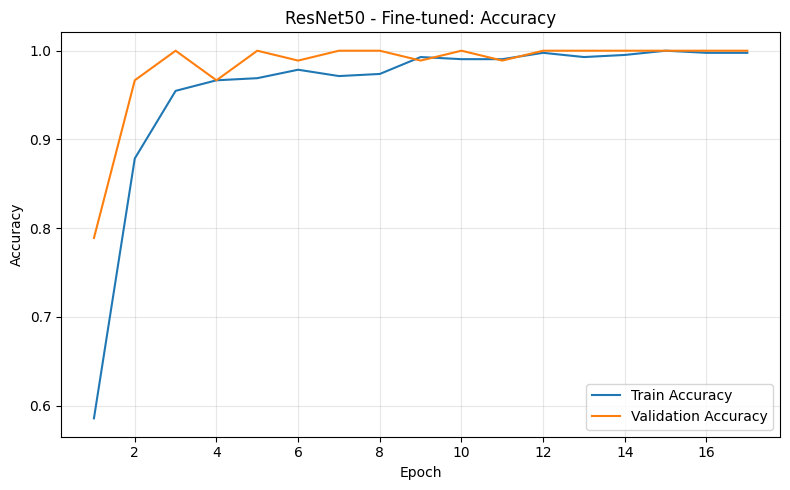

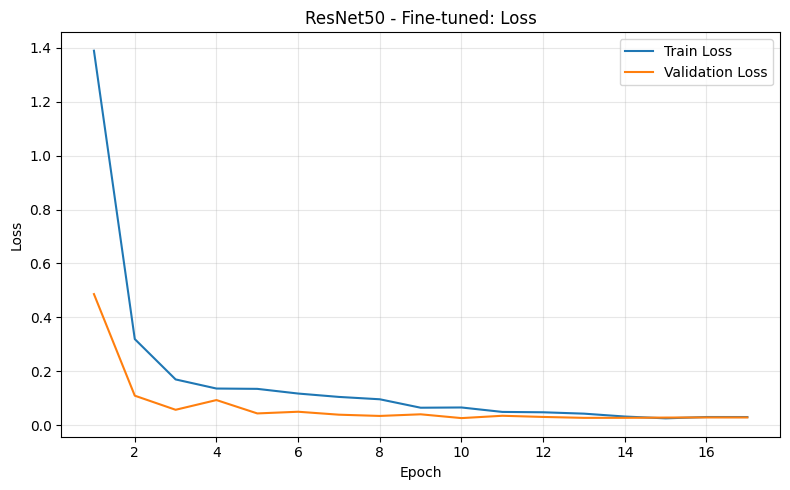


===== ResNet50_Fine-tuned: TEST CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        rock       1.00      1.00      1.00        30
       paper       1.00      1.00      1.00        30
    scissors       1.00      1.00      1.00        30

    accuracy                           1.00        90
   macro avg       1.00      1.00      1.00        90
weighted avg       1.00      1.00      1.00        90



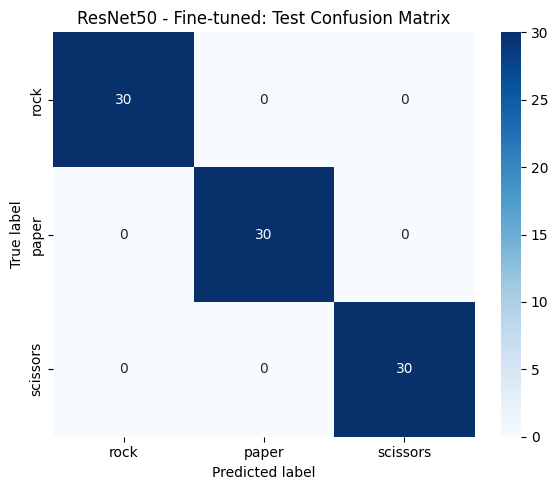

Fit diagnosis: No strong overfitting/underfitting signal from the final accuracy values.
Suggested action: Review curves and test metrics; keep regularization and early stopping.

Starting: EfficientNetB0 Frozen
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5649 - loss: 0.9601
Epoch 1: val_loss improved from None to 0.12410, saving model to /content/rps_pretrained_results/EfficientNetB0_Frozen/best_model.keras

Epoch 1: finished saving model to /content/rps_pretrained_results/EfficientNetB0_Frozen/best_model.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 68s 4s/step - accuracy: 0.7381 - loss: 0.6618 - val_accuracy: 0.9889 - val_loss: 0.1241 - learning_rate: 0.0010
Epoch 2/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9457 - loss: 0.2157
Epoch 2: val_loss improved from 0.12410 to 0.07938, saving model to /content/rps_pretrained_results/EfficientNetB0_Frozen/best_model.keras

Epoch 2: finished saving model to /content/rps_pre

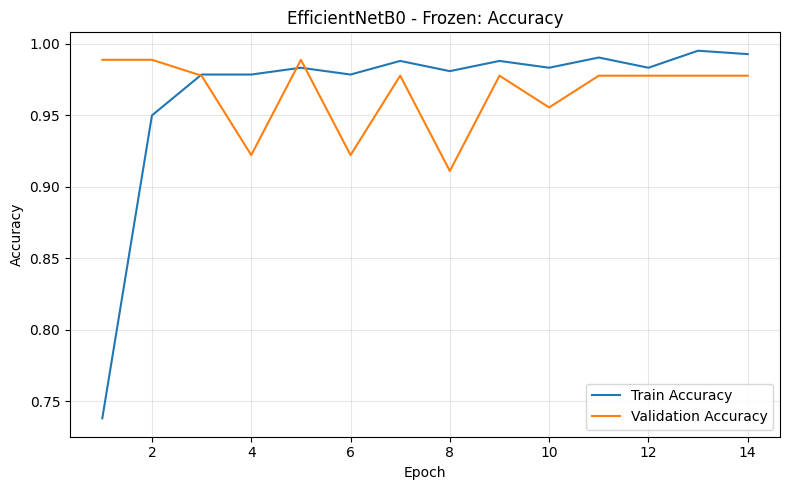

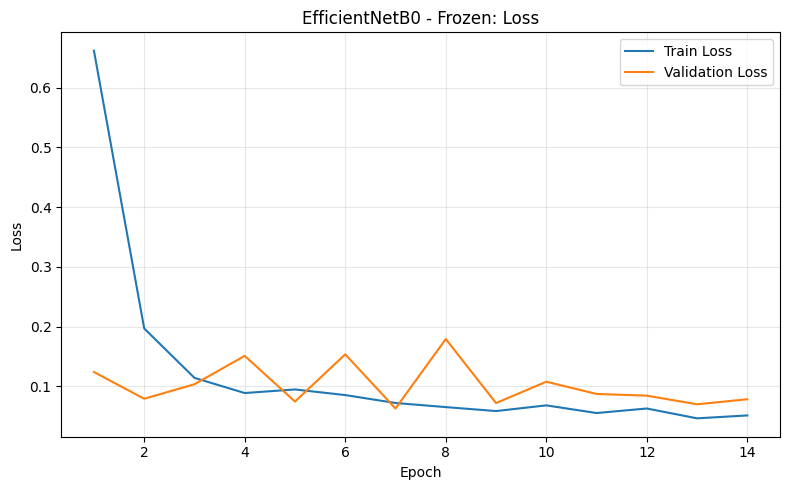


===== EfficientNetB0_Frozen: TEST CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        rock       1.00      1.00      1.00        30
       paper       1.00      1.00      1.00        30
    scissors       1.00      1.00      1.00        30

    accuracy                           1.00        90
   macro avg       1.00      1.00      1.00        90
weighted avg       1.00      1.00      1.00        90



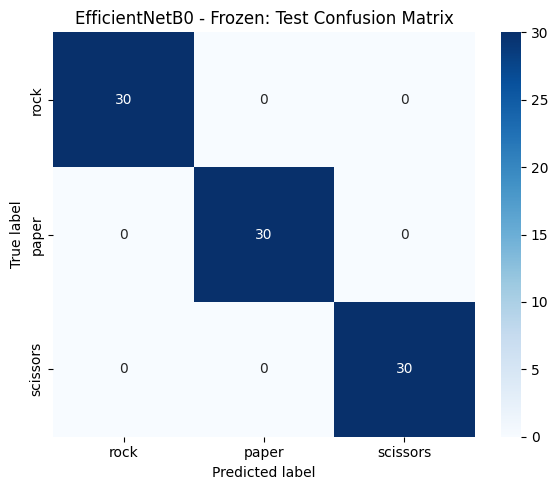

Fit diagnosis: No strong overfitting/underfitting signal from the final accuracy values.
Suggested action: Review curves and test metrics; keep regularization and early stopping.

Starting: EfficientNetB0 Fine-tuned
Epoch 1/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5826 - loss: 0.9370
Epoch 1: val_loss improved from None to 0.13821, saving model to /content/rps_pretrained_results/EfficientNetB0_Fine-tuned/best_model.keras

Epoch 1: finished saving model to /content/rps_pretrained_results/EfficientNetB0_Fine-tuned/best_model.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 66s 4s/step - accuracy: 0.7405 - loss: 0.6782 - val_accuracy: 0.9556 - val_loss: 0.1382 - learning_rate: 0.0010
Epoch 2/8
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9372 - loss: 0.2295
Epoch 2: val_loss improved from 0.13821 to 0.10466, saving model to /content/rps_pretrained_results/EfficientNetB0_Fine-tuned/best_model.keras

Epoch 2: finished saving model to /content/rps_pretrained_results/EfficientNetB0_Fine-t

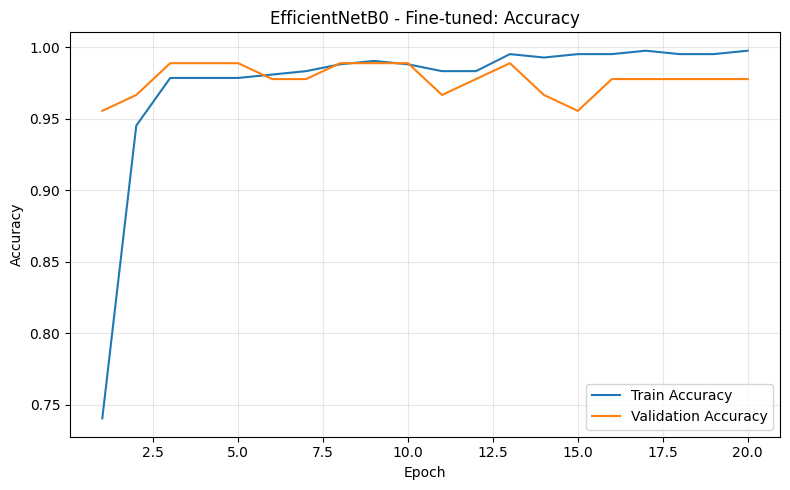

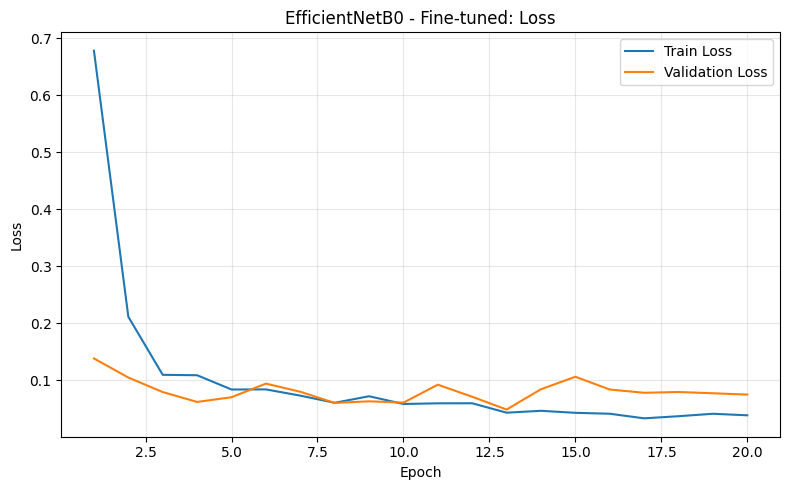


===== EfficientNetB0_Fine-tuned: TEST CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        rock       1.00      1.00      1.00        30
       paper       1.00      1.00      1.00        30
    scissors       1.00      1.00      1.00        30

    accuracy                           1.00        90
   macro avg       1.00      1.00      1.00        90
weighted avg       1.00      1.00      1.00        90



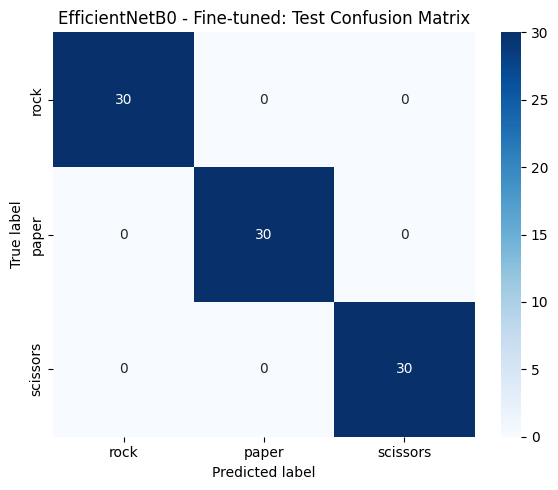

Fit diagnosis: No strong overfitting/underfitting signal from the final accuracy values.
Suggested action: Review curves and test metrics; keep regularization and early stopping.


,Architecture,Mode,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Epochs Completed,Train-Val Accuracy Gap,Fit Diagnosis,Suggested Action
0,MobileNetV2,Frozen,1.000000,1.000000,1.000000,1.000000,20,-0.007143,No strong overfitting/underfitting signal from...,Review curves and test metrics; keep regulariz...
2,ResNet50,Frozen,1.000000,1.000000,1.000000,1.000000,21,-0.003175,No strong overfitting/underfitting signal from...,Review curves and test metrics; keep regulariz...
4,EfficientNetB0,Frozen,1.000000,1.000000,1.000000,1.000000,14,0.015079,No strong overfitting/underfitting signal from...,Review curves and test metrics; keep regulariz...
3,ResNet50,Fine-tuned,1.000000,1.000000,1.000000,1.000000,17,-0.002381,No strong overfitting/underfitting signal from...,Review curves and test metrics; keep regulariz...
5,EfficientNetB0,Fine-tuned,1.000000,1.000000,1.000000,1.000000,20,0.019841,No strong overfitting/underfitting signal from...,Review curves and test metrics; keep regulariz...
1,MobileNetV2,Fine-tuned,0.988889,0.989247,0.988889,0.988886,30,0.000000,No strong overfitting/underfitting signal from...,Review curves and test metrics; keep regulariz...


In [14]:
# This cell trains all 6 models. It may take time.
for architecture in ["MobileNetV2", "ResNet50", "EfficientNetB0"]:
    for mode in ["Frozen", "Fine-tuned"]:
        print("\n" + "="*80)
        print("Starting:", architecture, mode)
        print("="*80)
        run_experiment(architecture, mode)

summary_df = pd.DataFrame(all_summary_rows)
summary_df.to_csv(OUTPUT_DIR / "final_comparison.csv", index=False)
display(summary_df.sort_values("Test Accuracy", ascending=False))

## 9. Final comparison chart

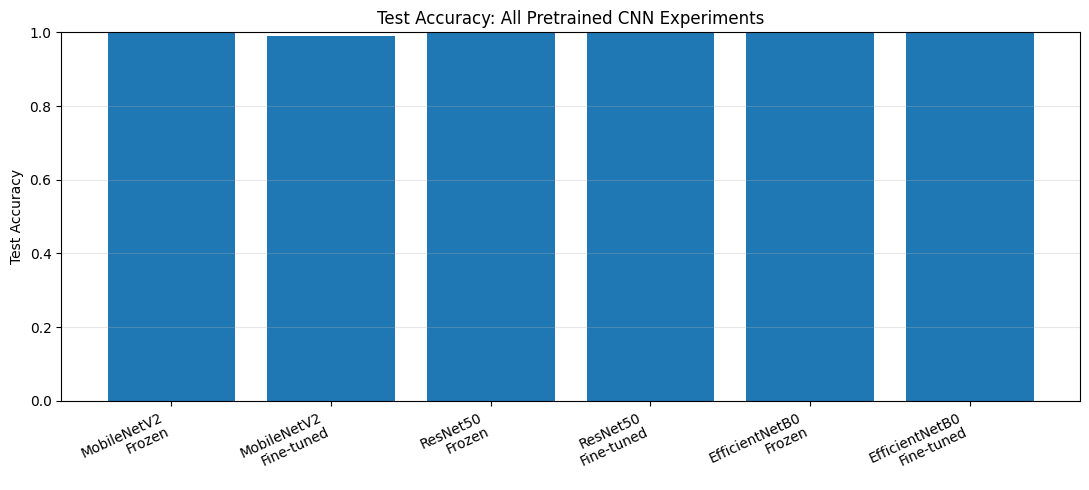

,Architecture,Mode,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Epochs Completed,Train-Val Accuracy Gap,Fit Diagnosis,Suggested Action
0,MobileNetV2,Frozen,1.000000,1.000000,1.000000,1.000000,20,-0.007143,No strong overfitting/underfitting signal from...,Review curves and test metrics; keep regulariz...
1,MobileNetV2,Fine-tuned,0.988889,0.989247,0.988889,0.988886,30,0.000000,No strong overfitting/underfitting signal from...,Review curves and test metrics; keep regulariz...
2,ResNet50,Frozen,1.000000,1.000000,1.000000,1.000000,21,-0.003175,No strong overfitting/underfitting signal from...,Review curves and test metrics; keep regulariz...
3,ResNet50,Fine-tuned,1.000000,1.000000,1.000000,1.000000,17,-0.002381,No strong overfitting/underfitting signal from...,Review curves and test metrics; keep regulariz...
4,EfficientNetB0,Frozen,1.000000,1.000000,1.000000,1.000000,14,0.015079,No strong overfitting/underfitting signal from...,Review curves and test metrics; keep regulariz...
5,EfficientNetB0,Fine-tuned,1.000000,1.000000,1.000000,1.000000,20,0.019841,No strong overfitting/underfitting signal from...,Review curves and test metrics; keep regulariz...


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [15]:
if (OUTPUT_DIR / "final_comparison.csv").exists():
    comparison = pd.read_csv(OUTPUT_DIR / "final_comparison.csv")
    plt.figure(figsize=(11, 5))
    labels = comparison["Architecture"] + "\n" + comparison["Mode"]
    plt.bar(labels, comparison["Test Accuracy"])
    plt.ylabel("Test Accuracy")
    plt.ylim(0, 1.0)
    plt.title("Test Accuracy: All Pretrained CNN Experiments")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "all_models_test_accuracy.png", dpi=150)
    plt.show()
    display(comparison)
else:
    print("Run the six experiments first.")

## 10. Download all results

In [16]:
# Creates one ZIP containing models, plots, classification reports, histories and comparison CSV.
zip_path = Path("/content/RPS_Pretrained_Results.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for file in OUTPUT_DIR.rglob("*"):
        if file.is_file():
            zf.write(file, file.relative_to(OUTPUT_DIR.parent))
print("Results ZIP:", zip_path)

Results ZIP: /content/RPS_Pretrained_Results.zip


In [17]:
from google.colab import files
files.download('/content/RPS_Pretrained_Results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. How to interpret overfitting and underfitting

- **Overfitting:** training accuracy keeps increasing while validation accuracy stalls or drops; training loss decreases while validation loss rises. This notebook already uses augmentation, dropout, L2 regularization, early stopping, and learning-rate reduction. If the gap remains large, collect more genuine varied images or reduce the number of unfrozen layers.
- **Underfitting:** both training and validation accuracy remain low and losses remain high. Check labels and preprocessing, train longer within the 30–50 epoch limit, or unfreeze a larger portion of the backbone with a small learning rate.
- Do not use the test set to tune the model. Use validation curves for model decisions; use the test set only for final evaluation.
- Report actual results from the generated CSVs and plots. Do not write expected or fabricated accuracy values.